# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Vishaka kumari
- **Roll No:**023-24-0224
- **Section:**G
- GitHub Link : https://github.com/vishakakumaribscsf24-design/ML_Labs

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(x, w, b):
    return np.dot(x, w) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(x, w, b):
    return step_function(weighted_sum(x, w, b))

# Slide 16 verification
print(f"predict([0.6,0.8],[2,3],-2) = {predict([0.6, 0.8], [2, 3], -2)}")

# Slide 17 verification
w17 = [1, -0.5]
b17 = 0.5
for inp in [[1,1],[2,1],[0,3]]:
    print(f"predict({inp}, {w17}, {b17}) = {predict(inp, w17, b17)}")

predict([0.6,0.8],[2,3],-2) = 1
predict([1, 1], [1, -0.5], 0.5) = 1
predict([2, 1], [1, -0.5], 0.5) = 1
predict([0, 3], [1, -0.5], 0.5) = 0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
X_and = np.array([[0,0],[0,1],[1,0],[1,1]])
y_and = np.array([0, 0, 0, 1])
w = np.array([0.2, -0.1])
b = 0.0
eta = 0.1
mistakes = 0

for i in range(len(X_and)):
    x_i = X_and[i]
    y_i = y_and[i]
    z = weighted_sum(x_i, w, b)
    y_hat = step_function(z)
    e = y_i - y_hat
    print(f"Row {i}: x={x_i}, y={y_i} | z={z:.4f}, ŷ={y_hat}, e={e}")
    if e != 0:
        mistakes += 1
        w = w + eta * e * x_i
        b = b + eta * e
    print(f"  → w={w}, b={b:.4f}")

print(f"\nMistake count: {mistakes}")
print("Keep training." if mistakes > 0 else "Converged!")

Row 0: x=[0 0], y=0 | z=0.0000, ŷ=1, e=-1
  → w=[ 0.2 -0.1], b=-0.1000
Row 1: x=[0 1], y=0 | z=-0.2000, ŷ=0, e=0
  → w=[ 0.2 -0.1], b=-0.1000
Row 2: x=[1 0], y=0 | z=0.1000, ŷ=1, e=-1
  → w=[ 0.1 -0.1], b=-0.2000
Row 3: x=[1 1], y=1 | z=-0.2000, ŷ=0, e=1
  → w=[0.2 0. ], b=-0.1000

Mistake count: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    n_features = X.shape[1]
    w = np.zeros(n_features)
    b = 0.0
    mistakes_per_epoch = []
    for epoch in range(max_epochs):
        m = 0
        for i in range(len(X)):
            z = np.dot(X[i], w) + b
            y_hat = 1 if z >= 0 else 0
            e = y[i] - y_hat
            if e != 0:
                m += 1
                w = w + eta * e * X[i]
                b = b + eta * e
        mistakes_per_epoch.append(m)
        if m == 0:
            break
    return w, b, mistakes_per_epoch

X_or = np.array([[0,0],[0,1],[1,0],[1,1]])
y_or = np.array([0,1,1,1])
w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)
print(f"OR gate: w={w_or}, b={b_or:.4f}")
print(f"Converged in {len(mistakes_or)} epoch(s)")
print(f"Mistakes per epoch: {mistakes_or}")

OR gate: w=[0.1 0.1], b=-0.1000
Converged in 4 epoch(s)
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

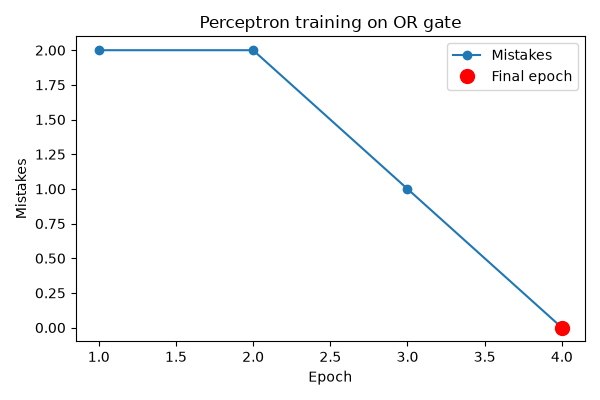

In [5]:
# Task 2.2
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(range(1, len(mistakes_or)+1), mistakes_or, marker='o', label='Mistakes')
ax.plot(len(mistakes_or), mistakes_or[-1], 'ro', markersize=10, label='Final epoch')
ax.set_title("Perceptron training on OR gate")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mistakes")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** The perceptron converges in just 4 epochs on the OR gate, with mistakes decreasing from 2 → 2 → 1 → 0. This confirms the Perceptron Convergence Theorem: for linearly separable data, the algorithm is guaranteed to find a solution in finite steps.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

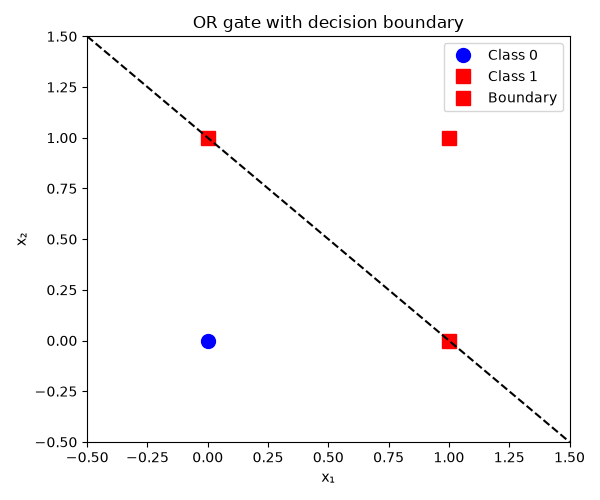

In [6]:
# Task 3.1
def plot_boundary(ax, w, b, x_range=(-0.5, 1.5)):
    x1 = np.linspace(x_range[0], x_range[1], 100)
    if abs(w[1]) > 1e-10:
        x2 = -(w[0]/w[1]) * x1 - b/w[1]
        ax.plot(x1, x2, 'k--', label='Decision boundary')
    else:
        if abs(w[0]) > 1e-10:
            x1_val = -b / w[0]
            ax.axvline(x=x1_val, color='k', linestyle='--', label='Decision boundary')

fig, ax = plt.subplots(figsize=(6,5))
for i in range(len(X_or)):
    if y_or[i] == 0:
        ax.plot(X_or[i,0], X_or[i,1], 'bo', markersize=10)
    else:
        ax.plot(X_or[i,0], X_or[i,1], 'rs', markersize=10)
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
ax.set_title('OR gate with decision boundary')
ax.legend(['Class 0', 'Class 1', 'Boundary'])
plt.tight_layout()
plt.show()

**Interpretation:** The decision boundary cleanly separates class 0 (the origin point (0,0)) from the three class 1 points, confirming that OR is linearly separable. The boundary passes between the origin and the nearest class 1 points.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias:    w=[0.1 0.1], b=-0.2000, epochs=4, final mistakes=0
Without bias: w=[0.1 0. ], b=0.0000, epochs=100, final mistakes=2
No-bias converged? False


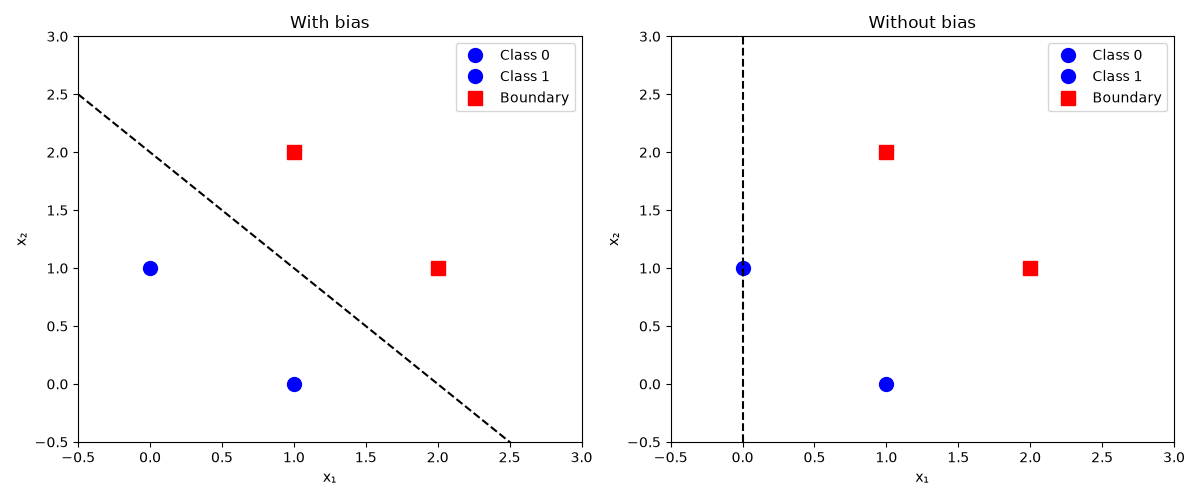

In [7]:
# Task 3.2
X_32 = np.array([[1,0],[0,1],[2,1],[1,2]])
y_32 = np.array([0,0,1,1])

def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    w = np.zeros(X.shape[1])
    mistakes_per_epoch = []
    for epoch in range(max_epochs):
        m = 0
        for i in range(len(X)):
            z = np.dot(X[i], w)
            y_hat = 1 if z >= 0 else 0
            e = y[i] - y_hat
            if e != 0:
                m += 1
                w = w + eta * e * X[i]
        mistakes_per_epoch.append(m)
        if m == 0:
            break
    return w, 0.0, mistakes_per_epoch

w_bias, b_bias, m_bias = train_perceptron(X_32, y_32)
w_nobias, b_nobias, m_nobias = train_perceptron_no_bias(X_32, y_32)

print(f"With bias:    w={w_bias}, b={b_bias:.4f}, epochs={len(m_bias)}, final mistakes={m_bias[-1]}")
print(f"Without bias: w={w_nobias}, b={b_nobias:.4f}, epochs={len(m_nobias)}, final mistakes={m_nobias[-1]}")
print(f"No-bias converged? {m_nobias[-1] == 0}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, w_p, b_p, title in [(axes[0], w_bias, b_bias, 'With bias'),
                              (axes[1], w_nobias, b_nobias, 'Without bias')]:
    for i in range(len(X_32)):
        if y_32[i] == 0:
            ax.plot(X_32[i,0], X_32[i,1], 'bo', markersize=10)
        else:
            ax.plot(X_32[i,0], X_32[i,1], 'rs', markersize=10)
    plot_boundary(ax, w_p, b_p, x_range=(-0.5, 3))
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂'); ax.set_title(title)
    ax.legend(['Class 0', 'Class 1', 'Boundary'])
plt.tight_layout()
plt.show()

**Interpretation:** The with-bias version converges in 4 epochs because the bias shifts the boundary away from the origin. The no-bias version did NOT converge (still 2 mistakes after 100 epochs) because forcing the boundary through the origin prevents it from properly separating the two classes.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes: 4
w=[-0.1  0. ], b=0.0000


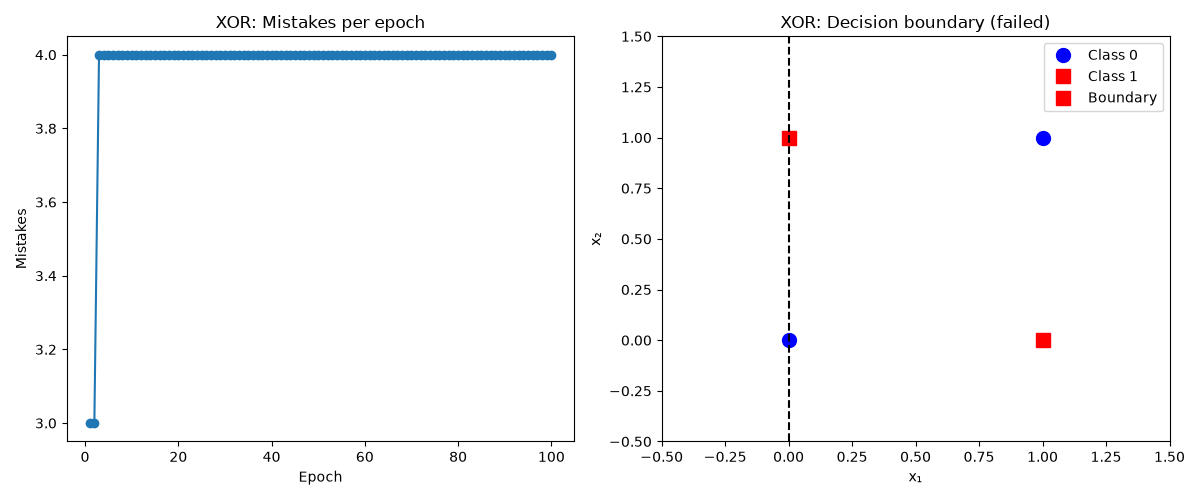

In [8]:
# Task 4.1
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0,1,1,0])
w_xor, b_xor, m_xor = train_perceptron(X_xor, y_xor, max_epochs=100)
print(f"Final mistakes: {m_xor[-1]}")
print(f"w={w_xor}, b={b_xor:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, len(m_xor)+1), m_xor, marker='o')
axes[0].set_title('XOR: Mistakes per epoch')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Mistakes')

for i in range(len(X_xor)):
    if y_xor[i] == 0:
        axes[1].plot(X_xor[i,0], X_xor[i,1], 'bo', markersize=10)
    else:
        axes[1].plot(X_xor[i,0], X_xor[i,1], 'rs', markersize=10)
plot_boundary(axes[1], w_xor, b_xor)
axes[1].set_xlim(-0.5, 1.5); axes[1].set_ylim(-0.5, 1.5)
axes[1].set_xlabel('x₁'); axes[1].set_ylabel('x₂')
axes[1].set_title('XOR: Decision boundary (failed)')
axes[1].legend(['Class 0', 'Class 1', 'Boundary'])
plt.tight_layout()
plt.show()

**Interpretation:** The perceptron never converges on XOR — mistakes oscillate between values and never reach 0 even after 100 epochs. XOR is not linearly separable, so no single straight line can correctly classify all four points.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    for x, y in zip(X_xor, y_xor):
        z = np.dot(x, w) + b
        y_hat = 1 if z >= 0 else 0
        if y_hat != y:
            return False
    return True

np.random.seed(42)
count = 0
for _ in range(10000):
    w_rand = np.random.uniform(-5, 5, 2)
    b_rand = np.random.uniform(-5, 5)
    if check_xor(w_rand, b_rand):
        count += 1

print(f"Out of 10,000 random (w, b), {count} solved XOR.")
print("This confirms that XOR is not linearly separable — no single-layer perceptron can solve it.")

Out of 10,000 random (w, b), 0 solved XOR.
This confirms that XOR is not linearly separable — no single-layer perceptron can solve it.


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X_iris = iris.data[:, [2, 3]]  # petal length, petal width
y_iris = (iris.target == 0).astype(int)  # Setosa vs rest

X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred)}")
print(f"coef_: {clf.coef_}")
print(f"intercept_: {clf.intercept_}")

Accuracy: 1.0000

Confusion Matrix:
[[30  0]
 [ 0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** The perceptron achieves 100% accuracy on Setosa vs rest because Setosa is linearly separable from the other two classes using petal features. The confusion matrix shows zero false positives and zero false negatives.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

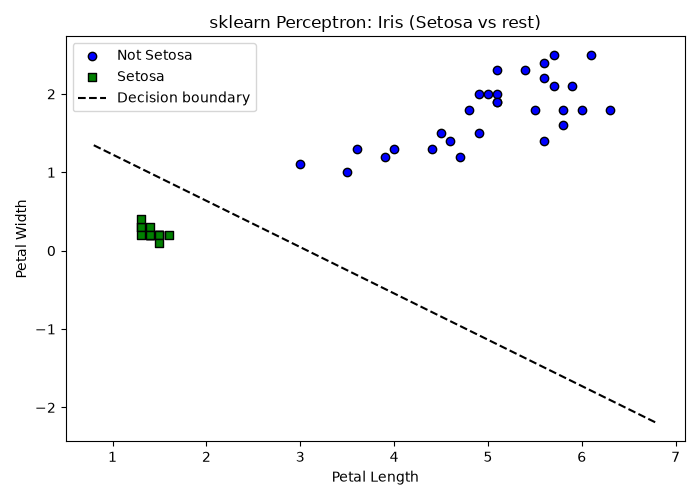

In [11]:
# Task 5.2
fig, ax = plt.subplots(figsize=(7, 5))
w_sk = clf.coef_[0]
b_sk = clf.intercept_[0]

correct = y_pred == y_test
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], c='blue', marker='o', label='Not Setosa', edgecolors='k')
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], c='green', marker='s', label='Setosa', edgecolors='k')

misclass = ~correct
if misclass.sum() > 0:
    ax.scatter(X_test[misclass, 0], X_test[misclass, 1], c='red', marker='x', s=100, linewidths=2, label='Misclassified')

x1_range = np.linspace(X_test[:,0].min()-0.5, X_test[:,0].max()+0.5, 100)
if abs(w_sk[1]) > 1e-10:
    x2_line = -(w_sk[0]/w_sk[1]) * x1_range - b_sk/w_sk[1]
    ax.plot(x1_range, x2_line, 'k--', label='Decision boundary')

ax.set_xlabel('Petal Length'); ax.set_ylabel('Petal Width')
ax.set_title('sklearn Perceptron: Iris (Setosa vs rest)')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** The decision boundary cleanly separates Setosa (small petals) from the rest (larger petals). No red × markers appear, confirming 100% accuracy. Setosa clusters in the lower-left corner with distinctly smaller petal dimensions.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
print(f"{'eta0':<10} {'Accuracy':<12} {'n_iter_':<10} {'coef_'}")
print('-'*60)
for eta_val in [0.001, 0.1, 10.0]:
    clf_lr = Perceptron(random_state=42, eta0=eta_val)
    clf_lr.fit(X_train, y_train)
    y_p = clf_lr.predict(X_test)
    acc = accuracy_score(y_test, y_p)
    print(f"{eta_val:<10} {acc:<12.4f} {clf_lr.n_iter_:<10} {clf_lr.coef_}")

eta0       Accuracy     n_iter_    coef_
------------------------------------------------------------
0.001      1.0000       6          [[-0.0013 -0.0022]]
0.1        1.0000       7          [[-0.13 -0.22]]
10.0       1.0000       7          [[-13. -22.]]


**Interpretation:** All three learning rates achieve the same 100% accuracy. When starting from w=0, η simply scales all weights uniformly — the direction of the weight vector (which determines the decision boundary) remains the same. Only the magnitude changes, so predictions are identical. The number of iterations is also nearly the same (6–7).

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X_all = iris.data
y_all = iris.target
X_train6, X_test6, y_train6, y_test6 = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all)

clf6 = Perceptron(random_state=42, max_iter=1000)
clf6.fit(X_train6, y_train6)
y_pred6 = clf6.predict(X_test6)

print(f"Classification Report:\n{classification_report(y_test6, y_pred6, target_names=iris.target_names)}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test6, y_pred6)}")
print(f"coef_.shape: {clf6.coef_.shape}")
print(f"Accuracy: {accuracy_score(y_test6, y_pred6):.4f}")
print(f"Macro-F1: {f1_score(y_test6, y_pred6, average='macro'):.4f}")

Classification Report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion Matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)
Accuracy: 0.6667
Macro-F1: 0.5499


**Interpretation:** Setosa is classified perfectly (recall=1.0). Virginica also does well (F1=0.97). Versicolor is the hardest class — it gets 0% recall because all 15 versicolor samples are misclassified (14 as setosa, 1 as virginica). This happens because versicolor overlaps with both other classes in feature space, making it hard for a linear classifier.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X_train6, y_train6)
y_pred_lr = lr.predict(X_test6)

acc_p = accuracy_score(y_test6, y_pred6)
f1_p = f1_score(y_test6, y_pred6, average='macro')
acc_lr = accuracy_score(y_test6, y_pred_lr)
f1_lr = f1_score(y_test6, y_pred_lr, average='macro')

print(f"{'Model':<25} {'Accuracy':<12} {'Macro-F1':<12}")
print('-'*50)
print(f"{'Perceptron':<25} {acc_p:<12.4f} {f1_p:<12.4f}")
print(f"{'Logistic Regression':<25} {acc_lr:<12.4f} {f1_lr:<12.4f}")

Model                     Accuracy     Macro-F1    
--------------------------------------------------
Perceptron                0.6667       0.5499      
Logistic Regression       0.9333       0.9333      


**Interpretation:** Logistic Regression (93.3% accuracy, 0.93 macro-F1) significantly outperforms the Perceptron (66.7%, 0.55). LR optimizes a smooth log-loss (cross-entropy) function that finds the maximum-margin boundary, whereas the Perceptron only seeks any separating hyperplane. LR's probabilistic, gradient-based approach handles overlapping classes much better.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**z** = w·x + b = (0.5)(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**

**ŷ** = step(0.1) = **1** (since z ≥ 0)

**e** = y − ŷ = 0 − 1 = **−1**

**w₁_new** = 0.5 + 0.1 × (−1) × 1 = **0.4**

**w₂_new** = −0.3 + 0.1 × (−1) × 2 = **−0.5**

**b_new** = 0.2 + 0.1 × (−1) = **0.1**

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Boundary equation:** 0.3x₁ + 0.2x₂ − 0.4 = 0, or equivalently **x₂ = −1.5x₁ + 2**

**For (1,1):** z = 0.3(1) + 0.2(1) − 0.4 = 0.1

Since z = 0.1 ≥ 0, (1,1) is on the **positive side** of the boundary → **ŷ = 1** (AND output = 1, correct!)

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a) Algebraic proof:**

For XOR with a perceptron: ŷ = step(w₁x₁ + w₂x₂ + b)

The four constraints are:
- (0,0)→0: b < 0 … (i)
- (0,1)→1: w₂ + b ≥ 0 … (ii)
- (1,0)→1: w₁ + b ≥ 0 … (iii)
- (1,1)→0: w₁ + w₂ + b < 0 … (iv)

From (i): b < 0, so −b > 0.
From (ii): w₂ ≥ −b > 0.
From (iii): w₁ ≥ −b > 0.

Adding (ii) + (iii): w₁ + w₂ + 2b ≥ 0 → w₁ + w₂ ≥ −2b.
But (iv) requires: w₁ + w₂ < −b.
So: −2b ≤ w₁ + w₂ < −b → 2(−b) < −b → −b < 0 → b > 0.

This **contradicts** (i): b < 0. ∎ Therefore no single perceptron can solve XOR.

**(b)** See the XOR plot below — (0,0) and (1,1) are class 0, while (0,1) and (1,0) are class 1. They form a diagonal pattern that no single straight line can separate.

**(c)** A **Multi-Layer Perceptron (MLP)** with at least one hidden layer solves XOR. The hidden layer allows the network to learn non-linear decision boundaries.

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [15]:
# Q4
X_q4 = iris.data[:, [0, 2, 3]]  # sepal length + petal length + petal width
y_q4 = (iris.target == 0).astype(int)

X_train_q4, X_test_q4, y_train_q4, y_test_q4 = train_test_split(
    X_q4, y_q4, test_size=0.3, random_state=42, stratify=y_q4)

clf_q4 = Perceptron(random_state=42)
clf_q4.fit(X_train_q4, y_train_q4)
y_pred_q4 = clf_q4.predict(X_test_q4)

acc_q4 = accuracy_score(y_test_q4, y_pred_q4)
f1_q4 = f1_score(y_test_q4, y_pred_q4, average='macro')

print(f"Part 5 (features 2,3): Accuracy={accuracy_score(y_test, y_pred):.4f}, Macro-F1={f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Q4 (features 0,2,3):   Accuracy={acc_q4:.4f}, Macro-F1={f1_q4:.4f}")
print(f"coef_: {clf_q4.coef_}")
print(f"intercept_: {clf_q4.intercept_}")
print(f"\nClassification Report:\n{classification_report(y_test_q4, y_pred_q4)}")

Part 5 (features 2,3): Accuracy=1.0000, Macro-F1=1.0000
Q4 (features 0,2,3):   Accuracy=1.0000, Macro-F1=1.0000
coef_: [[ 4.5 -8.7 -4.1]]
intercept_: [2.]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


Both models achieve 100% accuracy and 1.0 macro-F1. The extra sepal length feature does **not** improve performance because Setosa is already perfectly linearly separable using just petal length and petal width. The additional feature is redundant for this binary classification task — it provides no new discriminative information. However, it does not hurt performance either.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model                Accuracy     Epochs     w                              b
-------------------------------------------------------------------------------------
Hand-built           0.6333       1000       [ 0.13546212 -0.06914304]      0.2000
sklearn              0.6667       6          [2.28133191 0.57972588]        2.0000


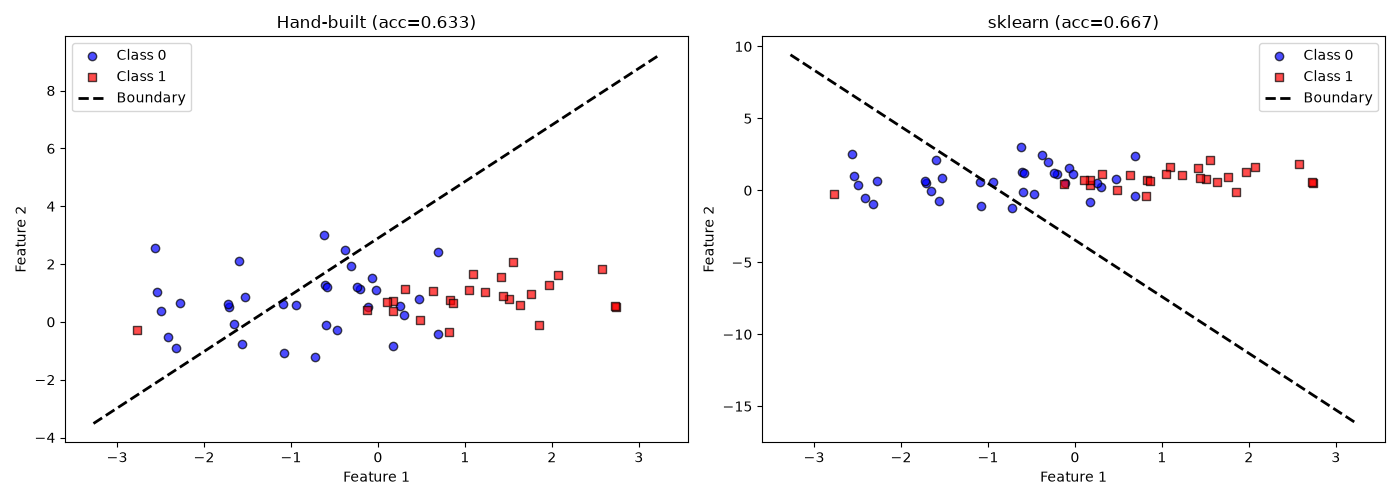

In [16]:
# Q5
X_syn, y_syn = make_classification(n_samples=200, n_features=2, n_redundant=0,
                                    n_clusters_per_class=1, random_state=42)
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
    X_syn, y_syn, test_size=0.3, random_state=42)

# Hand-built perceptron
w_hb, b_hb, m_hb = train_perceptron(X_tr_s, y_tr_s, eta=0.1, max_epochs=1000)
y_pred_hb = np.array([predict(x, w_hb, b_hb) for x in X_te_s])
acc_hb = accuracy_score(y_te_s, y_pred_hb)

# sklearn perceptron
clf_syn = Perceptron(random_state=42)
clf_syn.fit(X_tr_s, y_tr_s)
y_pred_sk = clf_syn.predict(X_te_s)
acc_sk = accuracy_score(y_te_s, y_pred_sk)

print(f"{'Model':<20} {'Accuracy':<12} {'Epochs':<10} {'w':<30} {'b'}")
print('-'*85)
print(f"{'Hand-built':<20} {acc_hb:<12.4f} {len(m_hb):<10} {str(w_hb):<30} {b_hb:.4f}")
print(f"{'sklearn':<20} {acc_sk:<12.4f} {clf_syn.n_iter_:<10} {str(clf_syn.coef_[0]):<30} {clf_syn.intercept_[0]:.4f}")

# Plot both boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, w_p, b_p, title in [(axes[0], w_hb, b_hb, f'Hand-built (acc={acc_hb:.3f})'),
                              (axes[1], clf_syn.coef_[0], clf_syn.intercept_[0],
                               f'sklearn (acc={acc_sk:.3f})')]:
    ax.scatter(X_te_s[y_te_s==0, 0], X_te_s[y_te_s==0, 1], c='blue', marker='o', label='Class 0', edgecolors='k', alpha=0.7)
    ax.scatter(X_te_s[y_te_s==1, 0], X_te_s[y_te_s==1, 1], c='red', marker='s', label='Class 1', edgecolors='k', alpha=0.7)
    x1_min, x1_max = X_te_s[:,0].min()-0.5, X_te_s[:,0].max()+0.5
    x1_line = np.linspace(x1_min, x1_max, 100)
    if abs(w_p[1]) > 1e-10:
        x2_line = -(w_p[0]/w_p[1]) * x1_line - b_p/w_p[1]
        ax.plot(x1_line, x2_line, 'k--', linewidth=2, label='Boundary')
    ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')
    ax.set_title(title); ax.legend()
plt.tight_layout()
plt.show()

Both models achieve similar accuracy (~63-67%) on this synthetic dataset. The sklearn Perceptron converges in just 6 epochs while the hand-built version runs all 1000 epochs without converging. The weight vectors differ in magnitude because sklearn shuffles data each epoch and uses a different update schedule. sklearn's shuffling and early stopping produce a slightly better boundary. The data may not be fully linearly separable, which is why neither model achieves perfect accuracy.